# Predicting the next trading day's direction

目标：在每个交易日收盘后，根据当天和过去的信息，预测下一交易日收盘时指数是否上涨。

## 1. Open the daily data

从本 notebook 所在的模块目录启动。每行是一个交易日，`Date` 是日期，`Close` 是收盘点位，`segment` 标明训练、验证或测试。

In [1]:
from pathlib import Path
import pandas as pd

feature_file = Path('../../data/processed/sp500_features.csv')
daily = pd.read_csv(feature_file, parse_dates=['Date']).sort_values('Date')
daily['segment'].value_counts()

segment
train    5083
val      1132
test     1132
Name: count, dtype: int64

## 2. Read three consecutive trading days

标签记在产生预测的那天。下一交易日收盘点位高于今天记为 `1`，低于或等于今天记为 `0`。先从表里手算，再用代码检查。

练习：9 月 3 日这行的答案是哪天知道的？9 月 4 日这行应该标成几？

In [2]:
example = daily.loc[daily['Date'].between('1997-09-03', '1997-09-05')]
example[['Date', 'Close', 'segment']].round({'Close': 2})

,Date,Close,segment
2,1997-09-03,927.86,train
3,1997-09-04,930.87,train
4,1997-09-05,929.05,train


## 3. Build the next-day label

数据已经按日期从早到晚排序。在每个 `segment`（训练、验证、测试）内部，把下一行的日期和收盘点位移到当前行。这样，同一行就能看到做预测的日期和核对答案的日期。

In [3]:
by_segment = daily.groupby('segment')
daily['target_date'] = by_segment['Date'].shift(-1)
daily['next_close'] = by_segment['Close'].shift(-1)

labeled = daily.dropna(subset=['next_close']).copy()
labeled['up'] = (labeled['next_close'] > labeled['Close']).astype(int)

`shift(-1)` 把下一行的值向上移一行。每段最后一个交易日在本段内没有下一行，所以先去掉这三个空答案，再比较点位。`up` 是模型要学的答案。训练时的输入只取预测当天已经知道的特征；`next_close` 和 `target_date` 仅供对齐和核对。

In [4]:
rows = labeled.loc[labeled['Date'].between('1997-09-03', '1997-09-05')]
rows[['Date', 'Close', 'target_date', 'next_close', 'up']].round({'Close': 2, 'next_close': 2})

,Date,Close,target_date,next_close,up
2,1997-09-03,927.86,1997-09-04,930.87,1
3,1997-09-04,930.87,1997-09-05,929.05,0
4,1997-09-05,929.05,1997-09-08,931.20,1


In [5]:
labeled['segment'].value_counts()

segment
train    5082
val      1131
test     1131
Name: count, dtype: int64

## 4. A simple baseline

先数一数训练集里涨和不涨各有多少天，选较常见的方向。接下来每个验证日都猜这个方向，用猜对的天数除以验证天数，得到准确率。

In [6]:
train = labeled.loc[labeled['segment'] == 'train']
val = labeled.loc[labeled['segment'] == 'val']

counts = train['up'].value_counts()
counts

up
1    2709
0    2373
Name: count, dtype: int64

In [7]:
baseline_guess = counts.idxmax()  # 出现次数最多的标签
correct = val['up'] == baseline_guess
print('Fixed prediction:', baseline_guess)
print('Correct predictions:', correct.sum(), '/', len(val))
print(f'Validation accuracy: {correct.mean():.2%}')

Fixed prediction: 1
Correct predictions: 625 / 1131
Validation accuracy: 55.26%


## 5. Logistic regression

先选三个收盘时已经知道的指标：上一交易日的对数收益率（log_ret_lag_1）、当前收盘点位相对 20 日均线的偏离（ma_ratio_20）、最近 21 个交易日的年化波动率（vol_21_ann）。先固定这些列，以便后面公平比较不同模型。

In [8]:
features = ['log_ret_lag_1', 'ma_ratio_20', 'vol_21_ann']
X_train = train[features]
y_train = train['up']
X_val = val[features]
X_train.head(3)

,log_ret_lag_1,ma_ratio_20,vol_21_ann
0,-0.011038,-0.029452,0.171044
1,-0.004659,0.002107,0.205698
2,0.030773,0.003739,0.205163


`X_train` 的每行是模型当天能看到的三项信息。`y_train` 是对应那行的真实答案。训练用这些历史记录学习；预测验证集时，只传入 `X_val`。

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 标准化和模型参数都只用训练集估计。
logistic_model = make_pipeline(StandardScaler(), LogisticRegression())
logistic_model.fit(X_train, y_train)
val_prediction = logistic_model.predict(X_val)

In [10]:
logistic_correct = val_prediction == val['up']
print('Correct predictions:', logistic_correct.sum(), '/', len(val))
print(f'Logistic regression accuracy: {logistic_correct.mean():.2%}')
print(f'Majority baseline accuracy: {correct.mean():.2%}')

Correct predictions: 627 / 1131
Logistic regression accuracy: 55.44%
Majority baseline accuracy: 55.26%


## 6. Random forest

使用相同的三个指标、训练日期和验证日期。每棵树依次比较特征值和阈值，平均所有树的上涨概率后得出分类结果。

In [11]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42)
forest_model.fit(X_train, y_train)
forest_prediction = forest_model.predict(X_val)

In [12]:
forest_correct = forest_prediction == val['up']
print('Correct predictions:', forest_correct.sum(), '/', len(val))
print(f'Random forest accuracy: {forest_correct.mean():.2%}')

Correct predictions: 632 / 1131
Random forest accuracy: 55.88%


In [13]:
forest_probabilities = forest_model.predict_proba(X_val)
print('Class order:', forest_model.classes_)
print('First validation day:', val['Date'].iloc[0].date())
print('Probabilities:', forest_probabilities[0].round(4))
print('Prediction:', forest_prediction[0])

Class order: [0 1]
First validation day: 2017-11-09
Probabilities: [0.4706 0.5294]
Prediction: 1


## 7. XGBoost

Fit shallow trees in sequence using the same three features and training dates. Each tree adds a correction to the running score. Evaluate on the same validation days as the baseline, logistic regression and random forest.

In [14]:
from xgboost import XGBClassifier

boost_model = XGBClassifier(n_estimators=50, max_depth=2, learning_rate=0.1, random_state=42)
boost_model.fit(X_train, y_train)
boost_prediction = boost_model.predict(X_val)

In [15]:
boost_correct = boost_prediction == val['up']
print('Correct predictions:', boost_correct.sum(), '/', len(val))
print(f'XGBoost accuracy: {boost_correct.mean():.2%}')

Correct predictions: 620 / 1131
XGBoost accuracy: 54.82%


In [16]:
first_day = X_val.iloc[[0]]
for tree_count in [1, 2, 50]:
    probabilities = boost_model.predict_proba(first_day, iteration_range=(0, tree_count))
    print(f'After {tree_count} trees: {probabilities[0, 1]:.2%} probability of up')

After 1 trees: 53.18% probability of up
After 2 trees: 53.07% probability of up
After 50 trees: 51.90% probability of up


## 8. Compare models on the validation period

Class 1 means up. Accuracy uses the predicted class; ROC AUC uses the probability of up to measure ranking. Select the highest validation ROC AUC among the three trained models, using unrounded scores. Use the test period for the final evaluation after model selection.

In [17]:
from sklearn.metrics import roc_auc_score

y_val = val['up']
logistic_p_up = logistic_model.predict_proba(X_val)[:, 1]
print(f'Logistic regression validation AUC: {roc_auc_score(y_val, logistic_p_up):.4f}')

Logistic regression validation AUC: 0.5009


In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {'logistic': logistic_model, 'forest': forest_model, 'xgboost': boost_model}
validation_predictions = pd.DataFrame(index=val.index)
validation_probabilities = pd.DataFrame(index=val.index)
validation_predictions['baseline'] = baseline_guess
validation_probabilities['baseline'] = y_train.mean()

for name, model in models.items():
    validation_predictions[name] = model.predict(X_val)
    validation_probabilities[name] = model.predict_proba(X_val)[:, 1]

In [19]:
metric_rows = []
for name in validation_predictions:
    predicted = validation_predictions[name]
    p_up = validation_probabilities[name]
    metric_rows.append({
        'model': name,
        'accuracy': accuracy_score(y_val, predicted),
        'precision': precision_score(y_val, predicted, zero_division=0),
        'recall': recall_score(y_val, predicted, zero_division=0),
        'f1': f1_score(y_val, predicted, zero_division=0),
        'roc_auc': roc_auc_score(y_val, p_up),
    })

validation_metrics = pd.DataFrame(metric_rows).set_index('model')
best_name = validation_metrics.loc[list(models), 'roc_auc'].idxmax()
print('Selected by validation ROC AUC:', best_name)
validation_metrics.round(4)

Selected by validation ROC AUC: logistic


,accuracy,precision,recall,f1,roc_auc
model,,,,,
baseline,0.5526,0.5526,1.0000,0.7118,0.5000
logistic,0.5544,0.5567,0.9504,0.7021,0.5009
forest,0.5588,0.5600,0.9408,0.7021,0.4998
xgboost,0.5482,0.5573,0.8864,0.6844,0.4998


## 9. Save validation results and a sample for backtesting

The example signals are from the validation period. The signal becomes available after the signal-date close and refers to the following trading day. The saved estimator includes any fitted preprocessing; it expects the three named features in their original order.

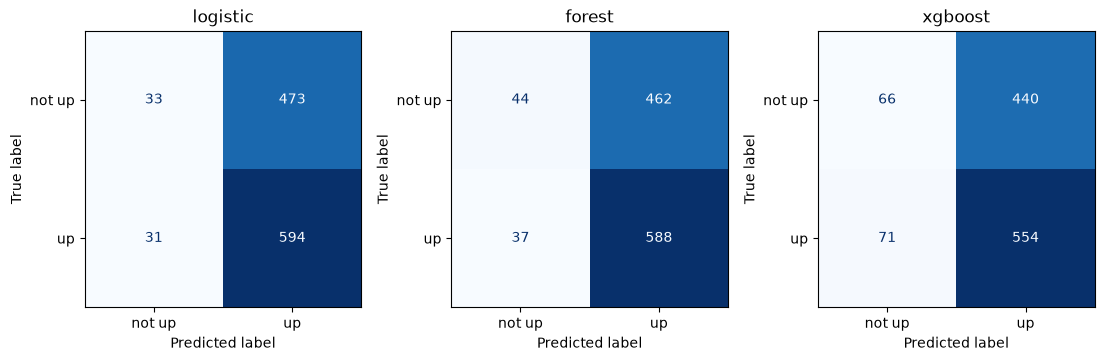

In [20]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import joblib

report_dir = Path('../../reports/2_RiseFallForecast')
for folder in ['metrics', 'figures', 'models', 'signals']:
    (report_dir / folder).mkdir(parents=True, exist_ok=True)
validation_metrics.to_csv(report_dir / 'metrics/validation_metrics.csv')

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), constrained_layout=True)
for ax, name in zip(axes, models):
    predicted = validation_predictions[name]
    report = classification_report(y_val, predicted, labels=[0, 1], target_names=['not up', 'up'], zero_division=0)
    (report_dir / 'metrics' / f'validation_{name}_report.txt').write_text(report, encoding='utf-8')
    ConfusionMatrixDisplay.from_predictions(y_val, predicted, labels=[0, 1], display_labels=['not up', 'up'], ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
fig.savefig(report_dir / 'figures/validation_confusion_matrices.png', dpi=150)
plt.show()

In [21]:
joblib.dump(models[best_name], report_dir / 'models/validation_selected.joblib')
validation_signals = pd.DataFrame({
    'signal_date': val['Date'],
    'target_date': val['target_date'],
    'p_up': validation_probabilities[best_name],
    'pred_up': validation_predictions[best_name],
})
sample = validation_signals.head(10)
sample.to_csv(report_dir / 'signals/validation_sample.csv', index=False)
sample.head(3)

,signal_date,target_date,p_up,pred_up
5083,2017-11-09,2017-11-10,0.546174,1
5084,2017-11-10,2017-11-13,0.546258,1
5085,2017-11-13,2017-11-14,0.546496,1


## 10. Final test and signal handoff

Keep the validation-selected model, feature order and original training fit fixed. Score the four pre-defined approaches on the held-out test dates. Use the selected model for the final signal file.

In [22]:
test = labeled.loc[labeled['segment'] == 'test']
X_test = test[features]
y_test = test['up']

test_predictions = pd.DataFrame(index=test.index)
test_probabilities = pd.DataFrame(index=test.index)
test_predictions['baseline'] = baseline_guess
test_probabilities['baseline'] = y_train.mean()

for name, model in models.items():
    test_predictions[name] = model.predict(X_test)
    test_probabilities[name] = model.predict_proba(X_test)[:, 1]

In [23]:
test_rows = []
for name in test_predictions:
    predicted = test_predictions[name]
    test_rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, predicted),
        'precision': precision_score(y_test, predicted, zero_division=0),
        'recall': recall_score(y_test, predicted, zero_division=0),
        'f1': f1_score(y_test, predicted, zero_division=0),
        'roc_auc': roc_auc_score(y_test, test_probabilities[name]),
    })

test_metrics = pd.DataFrame(test_rows).set_index('model')
test_metrics.to_csv(report_dir / 'metrics/test_metrics.csv')
print('Model selected earlier on validation:', best_name)
print('Test days:', len(y_test), '| Actual up days:', y_test.sum())
test_metrics.round(4)

Model selected earlier on validation: logistic
Test days: 1131 | Actual up days: 606


,accuracy,precision,recall,f1,roc_auc
model,,,,,
baseline,0.5358,0.5358,1.0000,0.6978,0.5000
logistic,0.5358,0.5375,0.9571,0.6884,0.5125
forest,0.5438,0.5424,0.9505,0.6906,0.5255
xgboost,0.5323,0.5370,0.9224,0.6788,0.5142


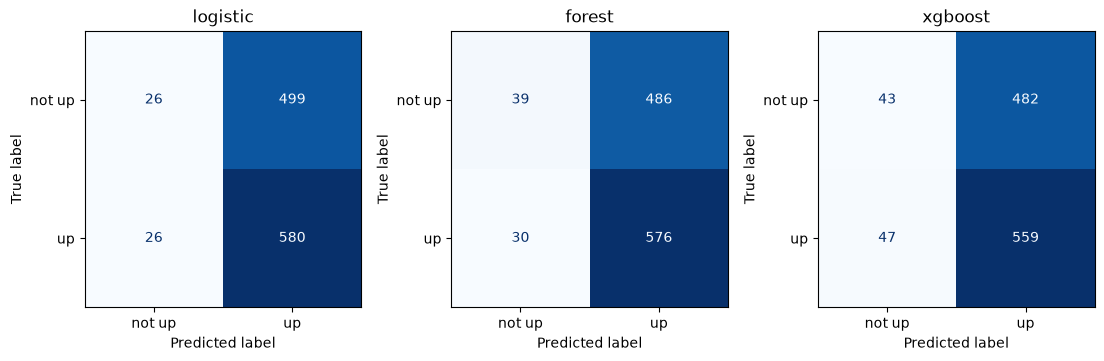

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), constrained_layout=True)
for ax, name in zip(axes, models):
    predicted = test_predictions[name]
    report = classification_report(y_test, predicted, labels=[0, 1], target_names=['not up', 'up'], zero_division=0)
    (report_dir / 'metrics' / f'test_{name}_report.txt').write_text(report, encoding='utf-8')
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=[0, 1], display_labels=['not up', 'up'], ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
fig.savefig(report_dir / 'figures/test_confusion_matrices.png', dpi=150)
plt.show()

In [25]:
test_signals = pd.DataFrame({
    'signal_date': test['Date'],
    'target_date': test['target_date'],
    'p_up': test_probabilities[best_name],
    'pred_up': test_predictions[best_name],
})
test_signals.to_csv(report_dir / 'signals/test_signals.csv', index=False)
test_signals.iloc[[0, -1]]

,signal_date,target_date,p_up,pred_up
6215,2022-05-11,2022-05-12,0.570441,1
7345,2026-11-12,2026-11-13,0.533397,1
